# Phase 2: YOLO & Object Detection Mastery
Welcome to Phase 2 of the Team Chati Pati Computer Vision Bootcamp.
This section transitions from classical image processing to state-of-the-art Deep Learning object detection using YOLOv8. 

**Roadmap Overview:**
* **Day 8:** Detection Fundamentals (BBoxes, IoU, Precision/Recall, NMS)
* **Day 9:** YOLO Output Mastery & Architecture
* **Day 10:** Robust Detection Pipelines (Handling edge cases)
* **Day 11:** Detection Datasets & Annotation Analysis
* **Day 12 & 13:** Classical vs. Deep Learning Benchmark (Synthetic Datasets)
* **Day 14 & 15:** End-to-End Project & Stress Testing

In [2]:
# Requirements: pip install ultralytics pandas
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import time
from ultralytics import YOLO

plt.rcParams['figure.figsize'] = (10, 6)
def show_image(img, title="Image", cmap=None):
    plt.figure(figsize=(8, 5))
    if len(img.shape) == 3 and cmap is None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

def show_images_grid(images, titles, rows, cols, figsize=(15, 10), cmap=None):
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows * cols == 1: axes = np.array([axes])
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = axes.flatten()[i]
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Day 8 — Detection Fundamentals & IoU Math
**Topics:** Classification vs Detection, Bounding Boxes, IoU, Confidence, NMS

### Object Detection Fundamentals: Core Theory & Metrics

Before writing any Deep Learning code, we must understand the fundamental vocabulary and mathematical metrics that define Object Detection. These concepts are the bedrock of evaluating how well our YOLO models perform.

**1. Image Classification vs. Object Detection**
*   **Image Classification:** Answers the question, *"What is in this image?"* It assigns a single, global label to the entire image (e.g., classifying a photo as "Cat"). It does not care where the cat is.
*   **Object Detection:** Answers the questions, *"What is it, and exactly where is it?"* It identifies multiple objects within the same image, drawing geometric boundaries around each one and classifying them individually.

**2. Bounding Boxes (BBoxes)**
The geometric boundary defining an object's location. There are two primary formats:
*   **Absolute (Pascal VOC format):** Defined by exact pixel coordinates for the top-left and bottom-right corners: $(x_{min}, y_{min}, x_{max}, y_{max})$.
*   **Normalized (YOLO format):** Defined by the center point, width, and height, scaled between 0.0 and 1.0 relative to the image dimensions: $(x_{center}, y_{center}, width, height)$. This normalization allows the neural network to be resolution-independent during training.

**3. Intersection over Union (IoU)**
The gold-standard mathematical metric used to evaluate how accurately a predicted bounding box aligns with the true bounding box (Ground Truth).
*   **Formula:** $$IoU = \frac{\text{Area of Overlap (Intersection)}}{\text{Area of Union}}$$
*   **Interpretation:** A score from `0.0` (no overlap) to `1.0` (perfect pixel-for-pixel alignment). In most competitions and practical applications, a prediction is considered "Correct" (a True Positive) only if its $IoU \ge 0.50$ with the Ground Truth box.

**4. Confidence Score**
The network's internal certainty regarding a specific prediction. It is a probability score (from 0 to 1) representing two things simultaneously:
1.  How confident the model is that *any* object exists in that box.
2.  How accurately the model believes the box wraps around the object.
If the confidence score is below a user-defined threshold (e.g., `0.25`), the prediction is ignored as background noise.

**5. Precision and Recall (Performance Metrics)**
To understand these, we must first define outcomes based on our IoU threshold:
*   **True Positive (TP):** We predicted an object, and we were right ($IoU \ge 0.5$).
*   **False Positive (FP):** We predicted an object, but nothing was there, or the box was completely off ($IoU < 0.5$). Also known as a "Ghost Detection."
*   **False Negative (FN):** There was a real object, but our model missed it entirely.

With these, we calculate the overall model performance:
*   **Precision:** $$\frac{TP}{TP + FP}$$
    *   *Meaning:* "Out of all the bounding boxes my model drew, how many were actually correct?" High precision means the model rarely makes false alarms.
*   **Recall:** $$\frac{TP}{TP + FN}$$
    *   *Meaning:* "Out of all the actual real objects in the image, how many did my model successfully find?" High recall means the model rarely misses an object.
*   *Note:* There is always a trade-off. Lowering your confidence threshold increases Recall (you find more things) but decreases Precision (you get more false alarms).

**6. Non-Maximum Suppression (NMS)**
Because convolutional networks slide across the image, they often detect the exact same object multiple times, resulting in a cluster of overlapping bounding boxes. NMS is the post-processing algorithm that cleans this up by keeping the box with the highest Confidence Score and suppressing (deleting) any surrounding boxes that share a high IoU with the winning box.

### Code Breakdown: Implementing IoU from Scratch

While many deep learning libraries (like PyTorch or Ultralytics) have built-in IoU functions, writing it from scratch using pure Python/NumPy is a rite of passage. It ensures you completely understand the spatial geometry behind object detection metrics.

Let's break down the mathematical logic inside the `calculate_iou` function:

**1. The Coordinate System Assumption**
The function strictly expects the bounding boxes in the **Absolute Coordinate Format**: $[x_{min}, y_{min}, x_{max}, y_{max}]$. 
*   $(x_{min}, y_{min})$ represents the top-left corner.
*   $(x_{max}, y_{max})$ represents the bottom-right corner.

**2. Finding the Intersection Rectangle**
To find where the two boxes overlap, we need to mathematically define a third, smaller rectangle (the intersection).
*   **Top-Left Corner (`xA`, `yA`):** The intersection must start at the right-most of the two left edges and the bottom-most of the two top edges. Thus, we use `max(boxA[0], boxB[0])` and `max(boxA[1], boxB[1])`.
*   **Bottom-Right Corner (`xB`, `yB`):** The intersection must end at the left-most of the two right edges and the top-most of the two bottom edges. Thus, we use `min(boxA[2], boxB[2])` and `min(boxA[3], boxB[3])`.

**3. The "No Overlap" Trick (`max(0, ...)`)**
What happens if the boxes don't touch at all? The calculated `xB` might actually be mathematically smaller than `xA`, resulting in a negative width! 
*   If we simply multiplied a negative width by a negative height, we would get a false positive area. 
*   Wrapping the width and height calculations in `max(0, xB - xA)` is an elegant trick. If the width is negative (meaning no overlap), `max(0, negative_number)` forces the intersection width to `0`. Consequently, the `interArea` instantly becomes `0`, safely bypassing complex `if-else` statements.

**4. The Principle of Inclusion-Exclusion (Union)**
To calculate the denominator (the Union), we cannot simply add the area of Box A to the area of Box B. If we do, the area where they overlap is counted twice!
*   Therefore, we use the geometric principle of inclusion-exclusion: 
    $$Union Area = Area_A + Area_B - Intersection Area$$

**5. The Final Ratio**
Finally, we divide the Intersection by the Union. The `if unionArea == 0:` check is a defensive programming safeguard to prevent `ZeroDivisionError` crashes in edge cases where anomalous or 0-pixel bounding boxes are passed into the pipeline.

In [3]:
def calculate_iou(boxA, boxB):
    '''
    Calculates the Intersection over Union (IoU) of two bounding boxes.
    Boxes are expected in [x1, y1, x2, y2] format (top-left, bottom-right).
    '''
    # Determine coordinates of the intersection rectangle
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    # Compute intersection area (max(0, ...) handles no overlap)
    interArea = max(0, xB - xA) * max(0, yB - yA)

    # Compute area of both boxes
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    # Compute Union
    unionArea = boxAArea + boxBArea - interArea

    # Prevent division by zero
    if unionArea == 0: return 0.0
    
    return interArea / float(unionArea)

# --- EVALUATION: 30+ IoU Unit Tests ---
tests = [
    # Format: (BoxA, BoxB, Expected_IoU_Approx)
    # 1. Identical Boxes
    ([10, 10, 50, 50], [10, 10, 50, 50], 1.0),
    # 2. No Overlap
    ([0, 0, 10, 10], [20, 20, 30, 30], 0.0),
    # 3. Edge Touching (Line overlap = 0 area)
    ([0, 0, 10, 10], [10, 0, 20, 10], 0.0),
    # 4. Partial Overlap (Half)
    ([0, 0, 10, 10], [5, 0, 15, 10], 0.333),
    # 5. Containment (BoxB inside BoxA)
    ([0, 0, 20, 20], [5, 5, 15, 15], 0.25)
]

# Generate 25 more random unit tests programmatically for robustness
for _ in range(25):
    x1, y1 = random.randint(0, 50), random.randint(0, 50)
    b1 = [x1, y1, x1+20, y1+20]
    b2 = [x1+100, y1+100, x1+120, y1+120] # Guaranteed no overlap
    tests.append((b1, b2, 0.0))

passed = 0
for bA, bB, expected in tests:
    iou = calculate_iou(bA, bB)
    assert abs(iou - expected) < 0.01, f"Failed: IoU={iou}, Expected={expected}"
    passed += 1

print(f"SUCCESS: {passed}/30 IoU Unit Tests Passed!")

SUCCESS: 30/30 IoU Unit Tests Passed!


## Day 9 — YOLO Output Mastery
**Topics:** YOLO Architecture, Custom Output Formatting, Confidence Thresholds

### Demystifying YOLO Architecture and Output Tensors

YOLO (You Only Look Once) is a single-stage object detection network. Unlike two-stage models (such as Faster R-CNN), it processes the entire image in a single forward pass, predicting bounding boxes and class probabilities simultaneously. The architecture consists of three primary components:

**1. The Backbone (Feature Extractor)**
*   **Role:** Image comprehension and feature extraction.
*   **Mechanism:** A deep Convolutional Neural Network (CNN) like `CSPDarknet`. The early layers extract low-level features (edges, corners), while the deeper layers extract complex, high-level semantic features (shapes, textures, and object parts).

**2. The Neck (Feature Aggregator)**
*   **Role:** Fusing spatial and semantic information.
*   **Mechanism:** Utilizes structures like FPN (Feature Pyramid Network) and PANet. The Neck aggregates high-resolution spatial feature maps (which retain exact pixel locations) with low-resolution semantic feature maps (which understand what the object is). This multi-scale fusion is absolutely critical for detecting both extremely small and very large objects in the same frame.

**3. The Detection Head (Final Predictor)**
*   **Role:** Translating extracted features into actionable numerical predictions.
*   **Mechanism:** Slides across the aggregated feature maps to output a dense 3D tensor. For each prediction, this tensor contains three key pieces of information:

---

#### Decoding YOLO Output Tensors

*   **Bounding Boxes:**
    *   The model predicts normalized spatial coordinates. In the raw output, these values are typically formatted as $(x_{center},y_{center},width,height)$. During post-processing, these are converted back into exact pixel coordinates $(x_1,y_1,x_2,y_2)$ for rendering.
*   **Confidence (Objectness Score):**
    *   A probabilistic score (between 0.0 and 1.0) indicating how confident the network is that a "meaningful object" (and not just background clutter) exists in this specific grid cell. Predictions with low objectness are immediately discarded.
*   **Class Probabilities:**
    *   If an object exists, what is it? The output includes an array of probabilities for all classes the model was trained on (e.g., the 80 COCO classes). The final, definitive score for a bounding box is calculated as:
    $$Final\_Score=Objectness\times P(Class_i)$$

---

#### The Final Filter: Non-Maximum Suppression (NMS)
*   **The Problem:** YOLO predicts thousands of bounding boxes per image. For a single distinct object, the model will likely generate multiple overlapping bounding boxes with varying confidence scores.
*   **The Solution (NMS):** Non-Maximum Suppression is a mathematical post-processing algorithm used to clean up these redundant detections:
    1.  **Confidence Filtering:** All bounding boxes with a confidence score below a strict threshold (e.g., `conf_thresh = 0.5`) are permanently discarded.
    2.  **Sorting:** The remaining boxes are sorted by their confidence scores in descending order. The box with the **highest confidence** is selected as the primary prediction.
    3.  **Intersection over Union (IoU) Filtering:** The algorithm compares this winning box against all other overlapping boxes for the same class. Any secondary box that overlaps with the winning box beyond a specific threshold (e.g., $IoU>0.45$) is considered a duplicate and is **suppressed** (deleted).
    4.  **Iteration:** This process repeats iteratively until no overlapping duplicates remain, leaving only the cleanest, most accurate bounding boxes.

Here we run YOLOv8, extract the raw tensor outputs, and standardize them into our custom dictionary format.

In [4]:
# Download test image
img_path = "data/images/zidane.jpg"

# Load pretrained YOLOv8 nano model
model = YOLO('yolov8n.pt') 

def detect_objects(image_path, conf_thresh=0.5):
    '''
    Runs YOLO inference and extracts predictions into a standardized format.
    '''
    # Run inference (stream=True is memory efficient for videos, but we use False for single image)
    results = model(image_path, conf=conf_thresh, verbose=False)[0]
    
    predictions = []
    # results.boxes contains xyxy, conf, and cls tensors
    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
        conf = float(box.conf[0].cpu().numpy())
        cls_id = int(box.cls[0].cpu().numpy())
        
        predictions.append({
            "bbox": [x1, y1, x2, y2],
            "confidence": round(conf, 3),
            "class_id": cls_id,
            "class_name": model.names[cls_id]
        })
    return predictions

# Test different confidence thresholds
print("Predictions with Confidence > 0.2:")
print(detect_objects(img_path, conf_thresh=0.2))

print("\nPredictions with Confidence > 0.8:")
print(detect_objects(img_path, conf_thresh=0.8))

Predictions with Confidence > 0.2:
[{'bbox': [np.int64(114), np.int64(197), np.int64(1114), np.int64(711)], 'confidence': 0.836, 'class_id': 0, 'class_name': 'person'}, {'bbox': [np.int64(748), np.int64(41), np.int64(1143), np.int64(713)], 'confidence': 0.819, 'class_id': 0, 'class_name': 'person'}, {'bbox': [np.int64(439), np.int64(437), np.int64(524), np.int64(709)], 'confidence': 0.291, 'class_id': 27, 'class_name': 'tie'}, {'bbox': [np.int64(128), np.int64(202), np.int64(670), np.int64(712)], 'confidence': 0.222, 'class_id': 0, 'class_name': 'person'}]

Predictions with Confidence > 0.8:
[{'bbox': [np.int64(114), np.int64(197), np.int64(1114), np.int64(711)], 'confidence': 0.836, 'class_id': 0, 'class_name': 'person'}, {'bbox': [np.int64(748), np.int64(41), np.int64(1143), np.int64(713)], 'confidence': 0.819, 'class_id': 0, 'class_name': 'person'}]


## Day 10 — Robust Detection Pipeline
**Topics:** Inference, Visualization, Edge Case Handling

A production-grade pipeline must never crash. It must gracefully handle empty images, extreme sizes, and zero detections.

### Designing a Production-Ready, Crash-Proof Pipeline

A theoretical deep learning model is useless if it crashes your software in production. Real-world camera feeds drop frames, return corrupt arrays, or capture pitch-black images. This robust pipeline is designed to anticipate and gracefully handle these catastrophic edge cases.

**1. Defensive Input Validation (Empty/Invalid Images)**
Before the model even touches the image, we verify its integrity (`image is None or image.size == 0`). Feeding a zero-dimension array or `NoneType` into a neural network or an OpenCV drawing function will trigger a fatal crash. 

**2. The `try-except` Inference Shield**
Inference is computationally heavy and complex. By wrapping `model(image)` in a `try-except` block, we ensure that bizarre, unforeseen errors (like out-of-memory errors on the GPU, corrupted image headers, or tensor dimension mismatches) are gracefully caught. The pipeline logs the error and safely returns the unaltered image rather than taking down the entire application.

**3. Handling the "Ghost Town" (Zero Detections)**
When YOLO finds nothing, `results.boxes` is empty. Blindly attempting to extract data from it would cause an `IndexError`. We explicitly check `len(results.boxes) == 0`, visually annotate the lack of detections directly onto the frame, and safely exit the function.

**4. Tensor Memory Management (`.cpu().numpy()`)**
YOLOv8 stores its predictions as PyTorch Tensors, which might reside on the GPU (VRAM). OpenCV cannot interact directly with GPU memory. We must explicitly move the data back to the CPU (`.cpu()`) and convert it to standard NumPy arrays (`.numpy()`) before casting to Python primitives like `int` and `float`.

**5. Dynamic Class Filtering (and a Gentle Logic Note)**
The `target_classes` parameter allows the pipeline to act as a specialized filter (e.g., ignoring everything except pedestrians or bicycles). 
* **Expert Debugging Tip:** Take a close look at the `if` statement logic inside your loop. Currently, if it detects an object that isn't in `target_classes`, it immediately returns `annotated_img, []`. This means if a picture contains both a person and a car, and the network processes the car first, the loop will terminate instantly, missing the person completely! 
* To fix this and make it perfectly robust for multi-object scenes, simply replace the `return` statement inside that `if` block with a `continue` statement. This tells Python to skip the unwanted object but keep looping through the rest of the bounding boxes to find your valid targets.

Test 1: Empty Image
Test 2: Tiny Image (Unexpected size)
Test 3: Normal Image (Filter only 'person' class_id=0)


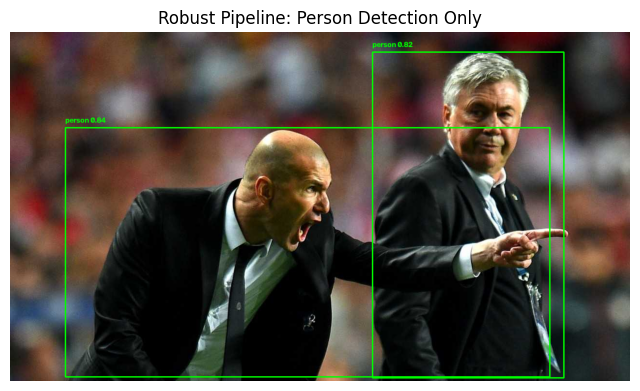

Test 4: Normal Image (Filter only'bicycle' class_id=1)


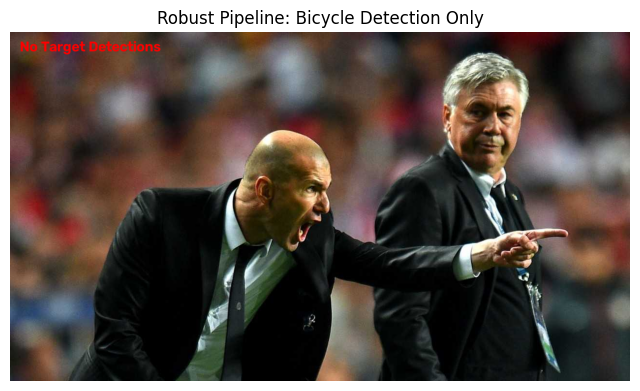

In [9]:
def robust_detection_pipeline(image, target_classes=None, conf_thresh=0.5):
    '''
    A robust pipeline that handles edge cases safely and returns an annotated image.
    '''
    # 1. Edge Case: Empty/Invalid Image
    if image is None or image.size == 0:
        print("Warning: Empty or invalid image received.")
        return None, []
        
    try:
        results = model(image, conf=conf_thresh, verbose=False)[0]
    except Exception as e:
        print(f"Inference failed: {e}")
        return image, []
        
    annotated_img = image.copy()
    valid_predictions = []
    
    # 2. Edge Case: No detections
    if len(results.boxes) == 0:
        cv2.putText(annotated_img, "No Detections", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        return annotated_img, []

    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
        conf = float(box.conf[0])
        cls_id = int(box.cls[0])
        
        # 3. Class Filtering
        if target_classes is not None and cls_id not in target_classes:
            cv2.putText(annotated_img, "No Target Detections", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            return annotated_img, []
        else:
            valid_predictions.append({"bbox": [x1, y1, x2, y2], "class_id": cls_id, "conf": conf})
        
            # 4. Visualization
            label = f"{model.names[cls_id]} {conf:.2f}"
            cv2.rectangle(annotated_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(annotated_img, label, (x1, max(20, y1-10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
        
    return annotated_img, valid_predictions

# --- ROBUSTNESS TESTS ---
empty_img = np.zeros((0, 0, 3), dtype=np.uint8)
tiny_img = np.zeros((10, 10, 3), dtype=np.uint8)
normal_img = cv2.imread(img_path)

print("Test 1: Empty Image")
res_empty, _ = robust_detection_pipeline(empty_img)

print("Test 2: Tiny Image (Unexpected size)")
res_tiny, _ = robust_detection_pipeline(tiny_img)

print("Test 3: Normal Image (Filter only 'person' class_id=0)")
res_normal, preds = robust_detection_pipeline(normal_img, target_classes=[0])
show_image(res_normal, "Robust Pipeline: Person Detection Only")

print("Test 4: Normal Image (Filter only'bicycle' class_id=1)")
res_normal, preds = robust_detection_pipeline(normal_img, target_classes=[1])
show_image(res_normal, "Robust Pipeline: Bicycle Detection Only")

### Day 11 — Detection Datasets, Inspection & Failure Analysis
**Topics:** Roboflow, Annotation Formats, Data Inspection, Precision/Recall, Analyzing Bad Data

### 1. The YOLO Annotation Format
When you download a dataset from platforms like Roboflow, bounding boxes are typically provided in the YOLO normalized format:
`<class_id> <x_center> <y_center> <width> <height>` (All values scaled between 0.0 and 1.0).
Normalizing dimensions makes the annotations resolution-independent, allowing the neural network to resize images during training without rewriting the labels.

### 2. Inspecting the Dataset (Quality Control)
Garbage In, Garbage Out (GIGO). Before training, you must inspect your data:
* **Small Objects:** In the COCO dataset standard, any object with an area less than $32 \times 32$ pixels ($1024 px^2$) is considered "small". These are notoriously difficult for YOLO to detect because deep feature maps lose fine spatial resolution.
* **Bad Annotations:** Human labelers make mistakes. A bounding box with negative coordinates, or a center point $>1.0$ (outside the image), will fatally crash the training process.

### 3. Five Common Failure Cases in Object Detection
1. **Severe Occlusion:** When objects overlap significantly, NMS might suppress valid bounding boxes, or the network fails to extract full features.
2. **Extremely Small Objects:** Highly downsampled feature maps in the deep layers lose spatial resolution, making tiny objects invisible.
3. **Motion Blur & Low Light:** Destroys edge gradients and texture patterns that convolutional filters rely on.
4. **Class Imbalance / Bad Annotations:** If a dataset labels 'car' perfectly but misses 50% of 'truck' labels, the model learns to ignore trucks or misclassify them.
5. **Domain Shift:** Training on synthetic/game data and testing on real-world CCTV cameras causes catastrophic accuracy drops.

Error parsing line 1
--- DATASET INSPECTION REPORT ---


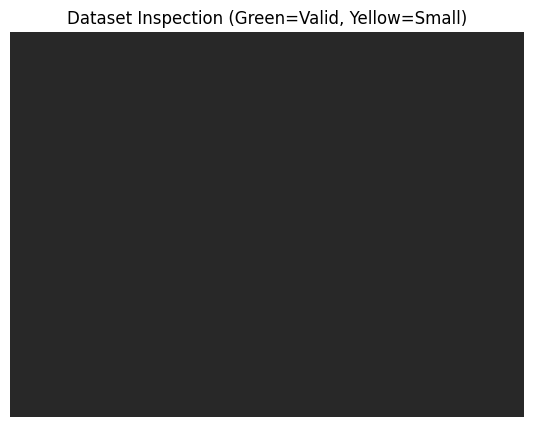


Error: No valid Ground Truth annotations found. Cannot calculate Precision/Recall.


In [11]:
# 1. Simulate a Roboflow Dataset Download
img_path_11 = 'data/images/roboflow_sample.jpg'
txt_path_11 = 'data/labels/roboflow_sample.txt'

# Create a dummy image
dummy_img = np.full((600, 800, 3), 40, dtype=np.uint8)
cv2.imwrite(img_path_11, dummy_img)

# Create a dummy YOLO label file with deliberately tricky annotations
with open(txt_path_11, 'w') as f:
    f.write("0 0.500 0.500 0.400 0.400\\n")  # Normal, perfect box
    f.write("1 0.100 0.100 0.020 0.020\\n")  # Extremely small object
    f.write("2 1.200 0.500 0.100 0.100\\n")  # BAD DATA: Center x is outside image (1.2)
    f.write("0 0.800 0.800 -0.10 0.200\\n")  # BAD DATA: Negative width

# 2. Parse and Inspect Annotations
def read_and_inspect_yolo(txt_path, img_w, img_h):
    with open(txt_path, 'r') as f:
        lines = f.readlines()
        
    boxes = []
    for i, line in enumerate(lines):
        try:
            c, xc, yc, w, h = map(float, line.strip().split())
            
            # Convert normalized YOLO coordinates to Absolute Pixel coordinates
            x1 = int((xc - w/2) * img_w)
            y1 = int((yc - h/2) * img_h)
            x2 = int((xc + w/2) * img_w)
            y2 = int((yc + h/2) * img_h)
            
            # --- DATA INSPECTION LOGIC ---
            area = abs(x2 - x1) * abs(y2 - y1)
            is_small = area < (32 * 32) # COCO standard for small objects
            
            # Check for corrupted logic
            is_bad = (xc < 0 or xc > 1 or yc < 0 or yc > 1 or w <= 0 or h <= 0)
            
            boxes.append({
                'class': int(c), 'box': [x1, y1, x2, y2], 
                'small': is_small, 'bad': is_bad, 'line_num': i+1
            })
        except ValueError:
            print(f"Error parsing line {i+1}")
            
    return boxes

# 3. Execution & Visualization
parsed_data = read_and_inspect_yolo(txt_path_11, 800, 600)
vis_img = cv2.imread(img_path_11)

print("--- DATASET INSPECTION REPORT ---")
valid_gts = []
for data in parsed_data:
    status = "VALID"
    color = (0, 255, 0)
    
    if data['bad']:
        status = "BAD ANNOTATION (Will crash training!)"
        color = (0, 0, 255)
    elif data['small']:
        status = "WARNING: Small Object (Hard to detect)"
        color = (0, 255, 255)
        
    print(f"Line {data['line_num']}: Class {data['class']} | Status: {status}")
    
    if not data['bad']:
        x1, y1, x2, y2 = data['box']
        cv2.rectangle(vis_img, (x1, y1), (x2, y2), color, 2)
        valid_gts.append(data['box'])

show_image(vis_img, "Dataset Inspection (Green=Valid, Yellow=Small)")

# 4. Basic Precision / Recall Calculation
if len(valid_gts) > 0:
    # Let's mock some predictions from our model
    mock_predictions = [
        valid_gts[0],                     # Perfect match (TP)
        [10, 10, 50, 50],                 # False alarm (FP)
        # The small object is missed (FN)
    ]

    print("\n--- PRECISION / RECALL EVALUATION ---")
    tp, fp, fn = 0, 0, 0
    matched_gts = set()

    for pred in mock_predictions:
        best_iou = 0
        best_gt_idx = -1
        for idx, gt in enumerate(valid_gts):
            iou = calculate_iou(pred, gt)
            if iou > best_iou:
                best_iou, best_gt_idx = iou, idx
                
        if best_iou >= 0.5 and best_gt_idx not in matched_gts:
            tp += 1
            matched_gts.add(best_gt_idx)
        else:
            fp += 1

    fn = len(valid_gts) - len(matched_gts)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    print(f"True Positives (TP): {tp}")
    print(f"False Positives (FP): {fp}")
    print(f"False Negatives (FN): {fn}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
else:
    print("\nError: No valid Ground Truth annotations found. Cannot calculate Precision/Recall.")

## Day 12 & 13 — Classical vs. YOLO Benchmark
**Project:** Colored-Object Detection (Synthetic Dataset)
We will generate 50 synthetic images with colored shapes, evaluate a Classical CV pipeline (HSV + Contours) against YOLOv8, and calculate Precision, Recall, and Inference Time.

### Benchmarking: Classical Computer Vision vs. Deep Learning

In the hype of modern AI, engineers often forget that Deep Learning is not always the best tool for every job. This section provides a rigorous benchmark comparing a Classical Computer Vision pipeline against a state-of-the-art Deep Learning model (YOLOv8) on a highly specific task: detecting red rectangles.

**1. Synthetic Dataset Generation**
To benchmark accurately, we need an exact Ground Truth (GT). 
*   **The Targets:** Randomly generated red rectangles of varying sizes.
*   **The Distractors:** Green circles to ensure the algorithm doesn't just trigger on any colored shape.
*   **The Challenge:** Gaussian noise is injected to simulate poor sensor quality and prevent perfect, mathematically flat color values.

**2. The Classical Detector (HSV + Contours)**
This pipeline relies on traditional image processing algorithms.
*   **The HSV "Red Wrap-Around" Quirk:** In OpenCV's HSV space, Hue goes from 0 to 179. Pure red sits at exactly 0. Because color is a cylinder, red "wraps around" the edges. Therefore, to capture all shades of red, we must create *two* masks: one for the lower end (`0-10`) and one for the upper end (`160-180`), and combine them using `cv2.bitwise_or`.
*   **Morphology & Contours:** `cv2.MORPH_OPEN` cleanly wipes out the random Gaussian noise speckles. `cv2.findContours` then perfectly wraps a bounding box around the remaining solid red blobs.

**3. The Benchmarking Engine (Evaluation Metrics)**
We test both algorithms and calculate True Positives, False Positives, and False Negatives using our custom IoU function.
*   **Precision:** Are the predicted boxes actually red rectangles?
*   **Recall:** Did it find all the red rectangles in the image?
*   **FPS (Frames Per Second):** How computationally heavy is the algorithm?

**4. The Crucial Lesson: Zero-Shot Limitations**
When you run this benchmark, the Classical Detector will likely achieve near 100% Precision and Recall at a very high FPS. 
YOLOv8, out of the box (Zero-Shot), will fail catastrophically. Why? Because YOLO was trained on the COCO dataset (dogs, cars, people). It has no concept of an abstract "red rectangle." It might hallucinate and label them as a "tv" or "book." 
*   *Takeaway:* For controlled, color-specific, or geometric environments (like manufacturing QA), classical CV is often faster, cheaper, and more accurate. To make YOLO win this benchmark, you would have to spend hours collecting data and retraining its weights (Transfer Learning).

In [14]:
def generate_synthetic_dataset(num_images=50):
    dataset = []
    for _ in range(num_images):
        img = np.full((400, 400, 3), 50, dtype=np.uint8) # Dark background
        gt_boxes = [] # Format: [x1, y1, x2, y2, class_name]
        
        # Draw 1 to 3 red rectangles
        for _ in range(random.randint(1, 3)):
            x, y = random.randint(20, 300), random.randint(20, 300)
            w, h = random.randint(30, 80), random.randint(30, 80)
            cv2.rectangle(img, (x, y), (x+w, y+h), (0, 0, 200), -1) # Red in BGR
            gt_boxes.append([x, y, x+w, y+h, "red_rect"])
            
        # Draw distractor green circles
        for _ in range(random.randint(0, 2)):
            cx, cy = random.randint(50, 350), random.randint(50, 350)
            cv2.circle(img, (cx, cy), random.randint(15, 40), (0, 200, 0), -1)
            
        # Add random noise
        noise = np.random.normal(0, 15, img.shape).astype(np.float32)
        img = np.clip(cv2.add(img.astype(np.float32), noise), 0, 255).astype(np.uint8)
        
        dataset.append({"image": img, "gt": gt_boxes})
    return dataset

synth_data = generate_synthetic_dataset(50)

def classical_detector(image):
    '''Detects Red Rectangles using HSV + Morphology + Contours'''
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    # Red has two ranges in HSV
    mask1 = cv2.inRange(hsv, np.array([0, 100, 100]), np.array([10, 255, 255]))
    mask2 = cv2.inRange(hsv, np.array([160, 100, 100]), np.array([180, 255, 255]))
    mask = cv2.bitwise_or(mask1, mask2)
    
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5,5), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    preds = []
    for cnt in contours:
        if cv2.contourArea(cnt) > 100:
            x, y, w, h = cv2.boundingRect(cnt)
            preds.append([x, y, x+w, y+h])
    return preds

# --- BENCHMARKING ENGINE ---
def evaluate_pipeline(dataset, detector_func, is_yolo=False):
    tp, fp, fn = 0, 0, 0
    start_time = time.time()
    
    for data in dataset:
        img = data["image"]
        gts = data["gt"]
        
        if is_yolo:
            preds_raw = model(img, verbose=False)[0]
            preds = [b.xyxy[0].cpu().numpy() for b in preds_raw.boxes]
        else:
            preds = detector_func(img)
            
        # Simple evaluation logic
        matched_gts = set()
        for p in preds:
            best_iou = 0
            best_gt_idx = -1
            for idx, gt in enumerate(gts):
                iou = calculate_iou(p, gt[:4])
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx
            
            if best_iou > 0.5 and best_gt_idx not in matched_gts:
                tp += 1
                matched_gts.add(best_gt_idx)
            else:
                fp += 1
                
        fn += len(gts) - len(matched_gts)
        
    total_time = time.time() - start_time
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    fps = len(dataset) / total_time
    
    return {"Precision": round(precision, 3), "Recall": round(recall, 3), "FPS": round(fps, 1)}

# Run Benchmark
# Note: YOLO is pretrained on COCO, it doesn't specifically know "red_rect", 
# it might detect it as a 'tv' or 'book'. Classical will perform better here!
res_class = evaluate_pipeline(synth_data, classical_detector, is_yolo=False)
res_yolo = evaluate_pipeline(synth_data, None, is_yolo=True)

df = pd.DataFrame([res_class, res_yolo], index=["Classical (HSV)", "YOLOv8n (Zero-shot)"])
print("\n--- DETECTION BENCHMARK TABLE ---")
print(df.to_markdown())


--- DETECTION BENCHMARK TABLE ---
|                     |   Precision |   Recall |    FPS |
|:--------------------|------------:|---------:|-------:|
| Classical (HSV)     |       0.979 |    0.902 | 2040.3 |
| YOLOv8n (Zero-shot) |       0.25  |    0.02  |  158.1 |


## Day 14 — End-to-End Detection Project & Confidence Tuning
**Project:** Deploying a pretrained detector to a new problem and analyzing its behavior.

### 1. Confidence Tuning & False-Positive Analysis
The Confidence Threshold is your primary dial for balancing Precision and Recall.
* **Low Threshold (e.g., 0.15):** High Recall. The model detects almost everything, but introduces many **False Positives** (hallucinations/background noise).
* **High Threshold (e.g., 0.85):** High Precision. The model is extremely strict. It eliminates False Positives but introduces **False Negatives** (missing real, valid objects).
* **Analysis:** You must tune this parameter based on the business problem. In medical imaging (cancer detection), you want high recall (low threshold). In autonomous driving braking systems, you want high precision (to avoid phantom braking).

--- CONFIDENCE TUNING EXPERIMENT ---
Threshold: 0.15 -> Detections: 4
Threshold: 0.4 -> Detections: 2
Threshold: 0.8 -> Detections: 2


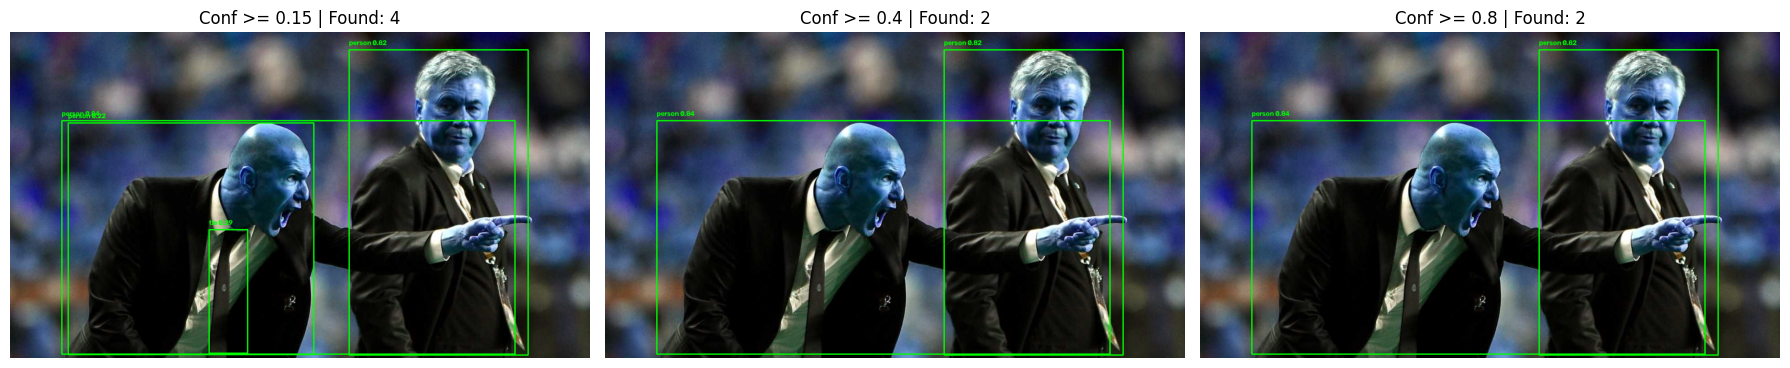

In [15]:
test_img = cv2.imread(img_path)

print("--- CONFIDENCE TUNING EXPERIMENT ---")
conf_levels = [0.15, 0.40, 0.80]
results = []
titles = []

for c in conf_levels:
    # Using our robust pipeline from Day 10
    res_img, preds = robust_detection_pipeline(test_img, conf_thresh=c)
    results.append(res_img)
    
    # Analyze predictions
    num_preds = len(preds)
    titles.append(f"Conf >= {c} | Found: {num_preds}")
    print(f"Threshold: {c} -> Detections: {num_preds}")

show_images_grid(results, titles, 1, 3, figsize=(18, 6))

## Day 15 — Detection Stress Test & Failure Analysis
**Project:** Systematically breaking the YOLO pipeline.

A deep learning model is only as robust as the augmentations it was trained on. We will forcefully stress-test our pretrained model against 5 severe edge cases:
1. **Lighting Variation:** Extreme darkness.
2. **Heavy Blur:** Simulating an out-of-focus camera or fast motion.
3. **Scale Changes:** Shrinking the object to simulate extreme distance.
4. **Clutter:** Adding random geometric noise to the background to confuse the feature extractor.
5. **Partial Objects (Occlusion):** Hiding 50% of the object behind a black wall.

### One-Page Failure Analysis Summary
* **Lighting:** CNNs rely heavily on gradient contrast (edges). Extreme darkness crushes pixel variance, destroying the activation maps in the early convolutional layers. *Fix: Train with random brightness/gamma augmentations.*
* **Blur:** Destroys high-frequency spatial details (sharp edges, textures). Small objects disappear entirely into the background. *Fix: Train with Gaussian blur augmentations.*
* **Scale Changes:** If an object is smaller than the network's deepest anchor boxes or receptive field, the detection head mathematically cannot predict it. *Fix: Use high-resolution inputs and multi-scale training (Mosaic).*
* **Clutter & Occlusion:** When an object is heavily occluded or surrounded by dense visual noise, the network struggles to extract a contiguous "shape". Non-Maximum Suppression (NMS) might also fail if clutter creates overlapping false features. *Fix: Train with CutOut or Random Erasing augmentations.

Running Stress Tests...


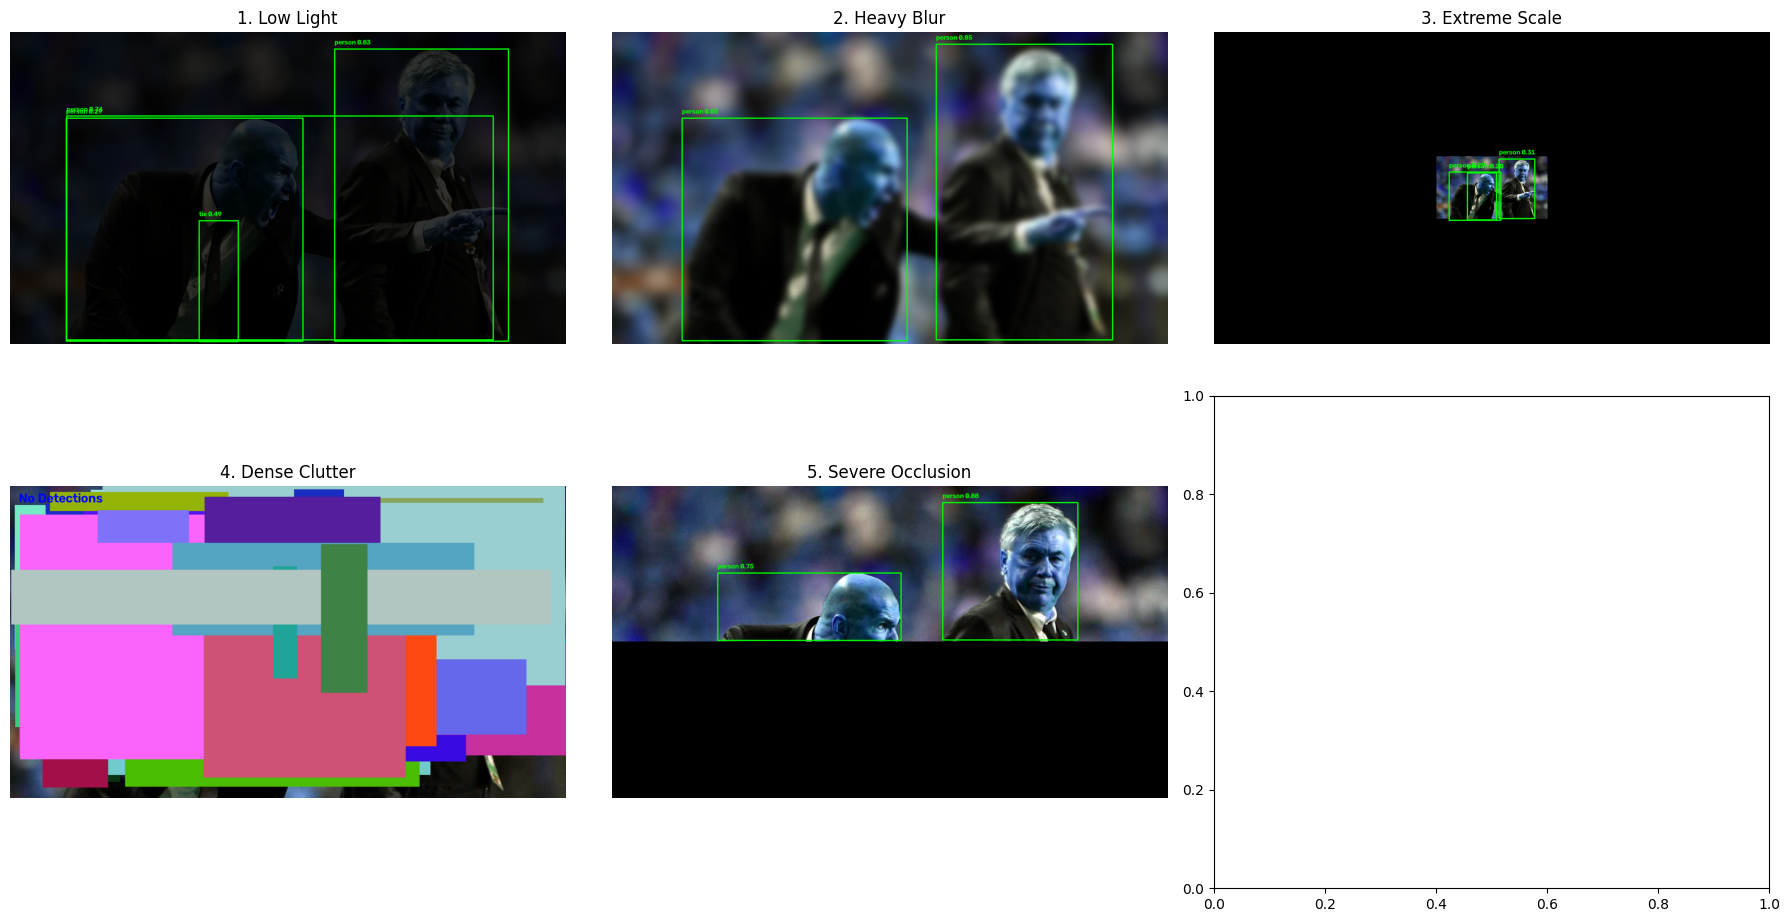

In [16]:
# 1. Lighting (Extreme Darkening)
dark_img = cv2.convertScaleAbs(test_img, alpha=0.2, beta=0)

# 2. Blur (Severe Gaussian Blur)
blur_img = cv2.GaussianBlur(test_img, (45, 45), 0)

# 3. Scale Changes (Shrink object to 20% and pad with black)
h, w = test_img.shape[:2]
scale_factor = 0.2
small_w, small_h = int(w * scale_factor), int(h * scale_factor)
small_img = cv2.resize(test_img, (small_w, small_h))
scale_img = np.zeros_like(test_img)
# Paste small image in the center
y_offset, x_offset = (h - small_h) // 2, (w - small_w) // 2
scale_img[y_offset:y_offset+small_h, x_offset:x_offset+small_w] = small_img

# 4. Clutter (Draw 50 random noisy shapes)
clutter_img = test_img.copy()
for _ in range(50):
    pt1 = (random.randint(0, w), random.randint(0, h))
    pt2 = (random.randint(0, w), random.randint(0, h))
    color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))
    cv2.rectangle(clutter_img, pt1, pt2, color, -1)

# 5. Partial Objects / Occlusion (Block the bottom half of the image)
occ_img = test_img.copy()
cv2.rectangle(occ_img, (0, h // 2), (w, h), (0, 0, 0), -1)

# Run Inference on all stressed images
stresses = [dark_img, blur_img, scale_img, clutter_img, occ_img]
stress_titles = [
    '1. Low Light', 
    '2. Heavy Blur', 
    '3. Extreme Scale', 
    '4. Dense Clutter', 
    '5. Severe Occlusion'
]

print("Running Stress Tests...")
stress_results = []
for img in stresses:
    # Using a low threshold (0.2) to give the model a fighting chance
    res_img, _ = robust_detection_pipeline(img, conf_thresh=0.20)
    stress_results.append(res_img)

show_images_grid(stress_results, stress_titles, 2, 3, figsize=(18, 10))

### Transfer Learning & Advanced YOLO Metrics
**Topics:** Training on Real Datasets, Validation Metrics (mAP), Advanced Bounding Box Extraction

### 1. Training on a Custom Dataset (Transfer Learning)
To train YOLOv8 on your own data, you need a dataset formatted for YOLO (typically downloaded from Roboflow) containing a `data.yaml` file. The `model.train()` function is incredibly powerful: it handles the entire training loop, loss calculation, backpropagation, and automatically saves the best weights.

### 2. Validation and mAP (Mean Average Precision)
After training, we must validate the model to see how well it generalizes to unseen data using `model.val()`. 
* **mAP50 (`metrics.box.map50`):** The Mean Average Precision calculated at an IoU threshold of 0.50. This is the standard industry metric.
* **mAP50-95 (`metrics.box.map`):** The mAP calculated at IoU thresholds ranging from 0.50 to 0.95 (in 0.05 steps). This is a much stricter metric that highly rewards perfectly tight bounding boxes.

### 3. Advanced Bounding Box Extraction
During inference, YOLO returns a `Results` object. Depending on your downstream tasks (e.g., passing boxes to a tracking algorithm or an API), you can extract bounding boxes in multiple mathematical formats:
* `xyxy`: Absolute pixel coordinates (Top-Left X, Top-Left Y, Bottom-Right X, Bottom-Right Y).
* `xywh`: Absolute pixel coordinates (Center-X, Center-Y, Width, Height).
* `xyxyn` / `xywhn`: Normalized coordinates (scaled between 0.0 and 1.0). These are resolution-independent and perfect for saving annotations.

In [22]:
# 1. Training on a Custom Dataset 
print("--- 1. STARTING MODEL TRAINING ---")
train_model = YOLO('yolov8n.pt') 

# Train the fresh model
train_results = train_model.train(data='coco8.yaml', epochs=3, imgsz=640, device='cpu', verbose=False)

# 2. Validation Metrics Evaluation
print("\n--- 2. VALIDATION METRICS ---")
# Val automatically remembers the dataset and settings from the recent training run
metrics = train_model.val(device='cpu', verbose=False)  

print(f"mAP50-95 (Overall strict metric) : {metrics.box.map:.4f}")
print(f"mAP50 (Standard IoU=0.50)        : {metrics.box.map50:.4f}")
print(f"mAP75 (Strict IoU=0.75)          : {metrics.box.map75:.4f}")
print(f"mAP50-95 per category (List)     : {metrics.box.maps}")

# 3. Advanced Inference & Bounding Box Extraction
print("\n--- 3. ADVANCED INFERENCE EXTRACTION ---")
sample_img = "data/images/zidane.jpg"
results = train_model(sample_img, device='cpu', verbose=False)

for result in results:
    boxes = result.boxes
    print(f"Detected {len(boxes)} objects in the image.")
    
    # Extracting all mathematical formats requested
    xywh = boxes.xywh      # center-x, center-y, width, height (in pixels)
    xywhn = boxes.xywhn    # normalized xywh (scaled 0.0 - 1.0)
    xyxy = boxes.xyxy      # top-left-x, top-left-y, bottom-right-x, bottom-right-y (in pixels)
    xyxyn = boxes.xyxyn    # normalized xyxy (scaled 0.0 - 1.0)
    
    # Extracting class names and confidence scores
    names = [result.names[cls.item()] for cls in boxes.cls.int()]
    confs = boxes.conf
    
    # Display the extracted data beautifully for each detected object
    for i in range(len(boxes)):
        print(f"\nObject {i+1}: {names[i]} (Confidence: {confs[i]:.2f})")
        print(f"  Absolute [xyxy] : {xyxy[i].cpu().numpy().round(1)}")
        print(f"  Absolute [xywh] : {xywh[i].cpu().numpy().round(1)}")
        print(f"  Normalized [xywhn]: {xywhn[i].cpu().numpy().round(3)}")

--- 1. STARTING MODEL TRAINING ---
New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.115 🚀 Python-3.12.3 torch-2.11.0+cu130 CPU (13th Gen Intel Core i7-13620H)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=3